# Detector readout: `collision_track` vs a `TimeFilter` tally

The project resolves detector detection times with **`collision_track`** — a per-event
record carrying exact `time`, `parent_id`, `delayed_group`. It is the right tool, and the
*only* tool, for the second-moment work (Rossi-$\alpha$ doubles, sibling multiplicity,
source provenance): those need to know which detections share a fission chain, and a tally
sums over histories and throws particle identity away.

But the **first-moment** detector time spectrum $g(t)$ is just a histogram of detection
times — and a `CellFilter`$\times$`TimeFilter` tally on an `absorption` score measures it
natively. This notebook runs the *same physics* (a uniform-core Watt pulse, $k=0.90$) both
ways at **matched total histories** and asks what the tally actually buys.

The honest answer, up front:

| | `collision_track` | `TimeFilter` tally |
|---|---|---|
| g(t) singles | ✅ (histogram prompt times) | ✅ (native) |
| per-bin precision at equal $N$ | Poisson $\sqrt{n}$ | across-batch `std_dev` — **about the same** |
| native error bars | ❌ (`batches=1`, parent_id recycles) | ✅ (multi-batch) |
| memory | bank $\propto$ detections | **fixed**, any $N$ |
| variance reduction (far detector) | ❌ (breaks pair stats) | ✅ singles only |
| **pairs / parent_id / provenance** | ✅ **only option** | ❌ impossible |

**Bottom line up front (§3–4):** the tally is unbiased and the weight-window variance
reduction is real but singles-only, regime-specific and setup-sensitive — *not* a uniform
win. We evaluate it honestly here and **stay on `collision_track` as the project's one
uniform detector readout**, keeping this as the record of what we tried.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

RESULTS = Path("../../results")
LABEL = "090"
d = np.load(RESULTS / f"tally-vs-collision-k{LABEL}.npz")

FIGURES_DIR = Path("../outputs/figures/method_comparison")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12, "legend.fontsize": 10,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.9, "lines.markersize": 6,
})

k = float(d["k"]); R = float(d["R"]); gap = float(d["gap"])
te = d["time_edges"]; dt = te[1] - te[0]
tc = 0.5 * (te[:-1] + te[1:])                      # bin centers [s]
nA = int(d["a_histories"]); nB = int(d["b_histories"]); nbatch = int(d["b_batches"])

# both in detections per source neutron per bin
gA = d["a_counts"] / nA                            # collision (prompt)
gA_err = np.sqrt(d["a_counts"]) / nA               # Poisson per bin
gB = d["b_mean"]                                    # tally mean
gB_err = d["b_std"]                                 # tally native std_dev

C_COLL, C_TALLY = "#d62728", "#1f77b4"
print(f"k={k:.2f}  R={R} cm  gap={gap} cm  | histories matched: A={nA:,}  B={nB:,} ({nbatch} batches)")

k=0.90  R=24.5 cm  gap=10.0 cm  | histories matched: A=200,000  B=200,000 (40 batches)


## 1. The two estimators measure the same $g(t)$

Overlaid prompt detection-time spectra, rebinned for readability (raw bins are sparse at
this demonstration budget). Collision: markers with Poisson error. Tally: line with native
`std_dev` band. They track each other across the whole prompt decay.

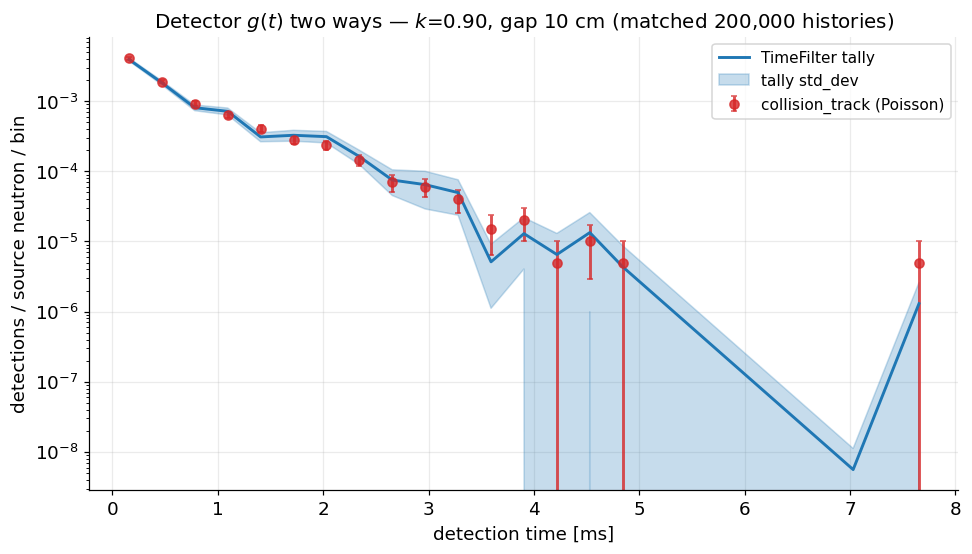

in-window integral  collision=8.8050e-03  tally=8.6221e-03  ratio=1.021
(small excess on collision = its count is unwindowed; tally sum is clipped to <=10 ms)


In [2]:
# Rebin by summing adjacent bins (raw bins are sparse at this demo budget).
# Counts/means add; their variances add in quadrature.
F = 8
tcb = tc[:(len(tc)//F)*F].reshape(-1, F).mean(axis=1) * 1e3   # ms
gA_b = (d["a_counts"][:(len(tc)//F)*F].reshape(-1, F).sum(axis=1)) / nA
gA_b_err = np.sqrt(d["a_counts"][:(len(tc)//F)*F].reshape(-1, F).sum(axis=1)) / nA
# tally: mean adds, variance adds (independent bins)
gB_b = d["b_mean"][:(len(tc)//F)*F].reshape(-1, F).sum(axis=1)
gB_b_err = np.sqrt((d["b_std"][:(len(tc)//F)*F].reshape(-1, F)**2).sum(axis=1))

fig, ax = plt.subplots(figsize=(9, 5.2))
m = gA_b > 0
ax.errorbar(tcb[m], gA_b[m], yerr=gA_b_err[m], fmt="o", color=C_COLL, capsize=2,
            alpha=0.8, label="collision_track (Poisson)")
mb = gB_b > 0
ax.plot(tcb[mb], gB_b[mb], "-", color=C_TALLY, label="TimeFilter tally")
ax.fill_between(tcb[mb], gB_b[mb] - gB_b_err[mb], gB_b[mb] + gB_b_err[mb],
                color=C_TALLY, alpha=0.25, label="tally std_dev")
ax.set_yscale("log")
ax.set_xlabel("detection time [ms]"); ax.set_ylabel("detections / source neutron / bin")
ax.set_title(f"Detector $g(t)$ two ways — $k$={k:.2f}, gap {gap:.0f} cm (matched {nA:,} histories)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "gt_overlay.png")
plt.show()

ratio = gA.sum() / gB.sum()
print(f"in-window integral  collision={gA.sum():.4e}  tally={gB.sum():.4e}  ratio={ratio:.3f}")
print("(small excess on collision = its count is unwindowed; tally sum is clipped to <=10 ms)")

## 2. At equal histories, precision is a wash — the tally's win is elsewhere

A fair head-to-head of per-bin relative uncertainty. The tally's native across-batch
`std_dev` and the collision method's Poisson $\sqrt{n}$ land on top of each other: **for
singles, the tally does not magically reduce variance at equal cost.** That is the honest
result, and it is worth stating plainly — the case for the tally is *not* "tighter error
bars on this run."

What the tally genuinely changes is **structural**:

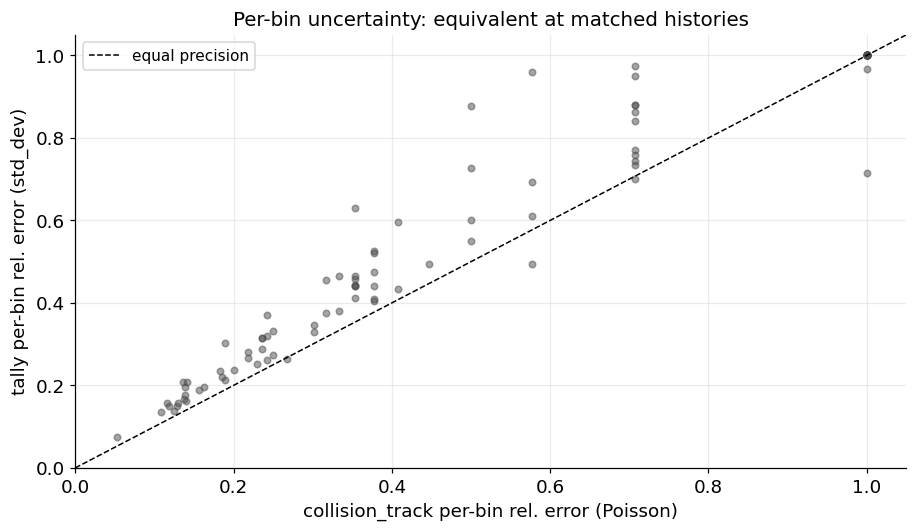

median per-bin rel error  collision=37.8%  tally=46.5%


In [3]:
m = (gA > 0) & (gB > 0)
relA = gA_err[m] / gA[m]
relB = gB_err[m] / gB[m]

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(relA, relB, s=18, alpha=0.5, color="0.3")
lim = [0, max(relA.max(), relB.max()) * 1.05]
ax.plot(lim, lim, "k--", lw=1, label="equal precision")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("collision_track per-bin rel. error (Poisson)")
ax.set_ylabel("tally per-bin rel. error (std_dev)")
ax.set_title("Per-bin uncertainty: equivalent at matched histories")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "precision_parity.png")
plt.show()

print(f"median per-bin rel error  collision={np.median(relA):.1%}  tally={np.median(relB):.1%}")

In [4]:
# The structural win: memory. The collision bank grows with detections; the tally
# statepoint is fixed-size regardless of history count.
bank_mb = int(d["a_bank_bytes"]) / 1e6
sp_kb = int(d["b_statepoint_bytes"]) / 1e3
n_events = int(d["a_n_total_events"])
per_event_b = int(d["a_bank_bytes"]) / max(n_events, 1)

print(f"collision_track.h5 : {bank_mb:.2f} MB  ({n_events:,} events, ~{per_event_b:.0f} B/event)")
print(f"tally statepoint    : {sp_kb:.0f} KB  (fixed: {len(gB)} time bins, any history count)")
print()
print("Scaling at fixed detection rate (this run's bytes/event), extrapolated:")
print(f"{'histories':>12} {'collision bank':>16} {'tally statepoint':>18}")
rate = n_events / nA
for N in [2e5, 1e6, 1e7, 1e8]:
    print(f"{N:>12,.0f} {rate*N*per_event_b/1e6:>13,.1f} MB {sp_kb:>15.0f} KB")

collision_track.h5 : 0.24 MB  (1,863 events, ~129 B/event)
tally statepoint    : 27 KB  (fixed: 256 time bins, any history count)

Scaling at fixed detection rate (this run's bytes/event), extrapolated:
   histories   collision bank   tally statepoint
     200,000           0.2 MB              27 KB
   1,000,000           1.2 MB              27 KB
  10,000,000          12.1 MB              27 KB
 100,000,000         120.6 MB              27 KB


## 3. Variance reduction (weight windows): tried, unbiased — but not a uniform win

The one thing a tally unlocks that `collision_track` cannot use is **variance reduction**.
For a far detector almost no neutron arrives, so $g(t)$ starves; weight windows **split**
neutrons heading toward the detector and **Russian-roulette** those wandering away, so more
(reduced-weight) particles reach it. This is valid for $g(t)$ *only because it is a
singles/linear quantity* — split/roulette destroy per-chain pairing, so weight windows can
**never** be used for the doubles/provenance work.

We ran it ([`weight_window_demo.py`](../../simulations/weight_window_demo.py)): a two-step
CADIS recipe (MAGIC generation on a $+Z$ corridor mesh, then apply) vs analog, matched
histories, on this exact geometry at $k=0.90$.

| geometry | analog $\sum_t g(t)$ | weight-window $\sum_t g(t)$ | mean agreement | variance / history | FOM (gen charged) |
|---|---|---|---|---|---|
| **gap 40 cm** | $2.61\times10^{-3}\ (\pm5.1\%)$ | $2.66\times10^{-3}\ (\pm3.9\%)$ | **$+0.30\sigma$** | $1.3\times$ tighter | $0.6\times$ (WW lost) |
| **gap 90 cm** | $9.06\times10^{-4}\ (\pm9.0\%)$ | $8.96\times10^{-4}\ (\pm6.2\%)$ | **$-0.10\sigma$** | $1.5\times$ tighter | $0.7\times$ (WW lost) |

**Unbiased — proven.** In both regimes the analog and weight-window means agree to within
$0.3\sigma$: the answer is statistically identical, the physics untouched. This is not luck;
it is a theorem. Every split ($w\to n$ copies of $w/n$) conserves weight exactly, and every
roulette conserves it in expectation ($p\cdot\frac{w}{p}+(1-p)\cdot0=w$). Weight is a passive
multiplicative tag that never feeds back into how collisions are sampled, so the expected
tally is identical for *any* importance map. **A bad map can wreck the variance; it can never
bias the mean.**

**But it did not improve uniformly — the textbook "VR just helps" intuition fails here.** The
per-history variance reduction was only $1.3$–$1.5\times$, and once the one-time
window-generation cost is charged the figure of merit dropped *below 1* — weight windows cost
more than they saved at this scale. Four reasons it is not the uniform win one expects:

1. **Singles only.** VR is legal for $g(t)$ but corrupts every pair/correlation quantity, so
   it can never cover the project uniformly — by construction it touches one estimator.
2. **Regime-dependent.** It helps only where analog starves (far detector, deep subcritical);
   near or well-fed it ties or loses. The FOM verdict even *flips with budget* (a 60k-history
   run showed FOM $1.4\times$, the 240k runs $<1$) — the opposite of a stable, uniform gain.
3. **Geometry caps it.** The detector sits across a **void**, so the loss is *geometric*
   (solid angle, a few-hundred-$\times$ ceiling), not *attenuation* — the deep-penetration
   shielding regime where weight windows deliver orders of magnitude. A void gives VR little
   to bite on.
4. **Setup-sensitive.** Even that modest ceiling needs a *directional* importance map
   (FW-CADIS / a fine angular mesh) and production-scale histories to amortize generation — a
   per-geometry tuning project, the antithesis of a uniform method.

## 4. Decision: `collision_track` stays the uniform method

We standardize the whole project on **`collision_track`**, and deliberately do **not** adopt
tallies or variance reduction for general work. The case, end to end:

* **Tallies cover strictly *less*, not more.** They tie `collision_track` on singles precision
  (§1–2) and **cannot** produce any second-moment quantity — Rossi-$\alpha$ doubles, sibling
  multiplicity, `parent_id`→birth provenance — because they discard the per-event identity
  those need. Adopting them would mean running *two* parallel pipelines (tally for singles,
  collision_track for pairs) to gain nothing on the singles side.
* **The lone tally-only advantage — variance reduction — is singles-only, regime-specific,
  geometry-capped, and setup-sensitive** (§3). It is unbiased and occasionally helps the
  starved far-detector corner, but it is the opposite of a uniform improvement, and that
  corner is exactly where ACDC is already the only viable estimator.
* **One validated pipeline beats a marginal, conditional optimization.** A single trusted
  data path — one format, one set of analysis code, every moment covered — is worth far more
  than a per-regime VR tax that requires a second machinery to maintain.

So `collision_track` is the project's uniform detector readout. The tally cross-check
(`greens_sweep --tally-gt`) and this evaluation (`tally_vs_collision.py`,
`weight_window_demo.py`) are kept as the **reproducible record of what we tried and why it
isn't adopted** — and as a ready starting point should a future far-detector ACDC study ever
make the trade worthwhile.